# PJM Power Market Explorer

### An Exploratory Analysis of Day-Ahead and Real-Time Power Market Dynamics

This project analyzes hourly PJM electricity market data to examine price behavior, congestion, system load, load forecast accuracy, Day-Ahead versus Real-Time price spreads, and generation by fuel type.

The analysis focuses on 12 major PJM hubs on August 18, 2026, with additional Day-Ahead data from August 19 used in the data preparation process.

---

## 1. Project Overview

### Objectives

This project investigates the following questions:

- How does Day-Ahead LMP change throughout the day?
- How do Day-Ahead prices differ across PJM hubs?
- How does congestion vary across locations?
- How strongly is system load associated with Day-Ahead LMP?
- How accurate was the selected pre-operating-day PJM load forecast?
- When did Day-Ahead and Real-Time prices diverge the most?
- How did generation by fuel type co-move with Day-Ahead LMP?

### Data Sources

The analysis uses PJM market data covering:

- Day-Ahead Locational Marginal Prices
- Real-Time Hourly Locational Marginal Prices
- Metered RTO Load
- Historical Load Forecasts
- Generation by Fuel Type

---

## 2. Data Loading & Cleaning

Raw PJM datasets are loaded and transformed into consistent hourly datasets for market analysis.

In [6]:
import pandas as pd              # Data manipulation and analysis
import matplotlib.pyplot as plt  # Data visualization

In [7]:
# Load Day-Ahead LMP data
da_818 = pd.read_csv("/content/PJM_DA_LMP_2026-08-18.csv")  # August 18 DA LMP
da_819 = pd.read_csv("/content/PJM_DA_LMP_2026-08-19.csv")  # August 19 DA LMP

# Load system load data
load_raw = pd.read_csv("/content/08-18-2026 hrl_load_metered.csv")  # Actual metered load

# Load historical load forecasts
forecast_hist = pd.read_csv("/content/081826load_frcstd_hist.csv")  # Forecast vintages

# Load Real-Time LMP data
rt_raw = pd.read_csv("/content/rt_hrl_lmps.csv")  # Hourly RT LMP

# Load generation mix data
fuel_raw = pd.read_csv("/content/081826gen_by_fuel.csv")  # Generation by fuel type

### 2.1 Day-Ahead LMP

In [8]:
# Combine the two Day-Ahead datasets
da = pd.concat(
    [da_818, da_819],  # Stack both dates vertically
    ignore_index=True  # Create a new continuous index
)

# Convert the Time column to datetime
da["Time"] = pd.to_datetime(
    da["Time"]  # Convert text timestamps into pandas datetime values
)

# Sort observations by hub and time
da = da.sort_values(
    ["Location Name", "Time"]  # Sort first by hub, then chronologically
).reset_index(drop=True)       # Reset row numbers

da.head()

,Time,Interval Start,Interval End,Market,Location Id,Location Name,Location Short Name,Location Type,LMP,Energy,Congestion,Loss
0,2026-08-18 00:00:00-04:00,2026-08-18 00:00:00-04:00,2026-08-18 01:00:00-04:00,DAY_AHEAD_HOURLY,34497125,AEP GEN HUB,AEP GEN HUB,HUB,41.657713,42.01,0.720794,-1.073081
1,2026-08-18 01:00:00-04:00,2026-08-18 01:00:00-04:00,2026-08-18 02:00:00-04:00,DAY_AHEAD_HOURLY,34497125,AEP GEN HUB,AEP GEN HUB,HUB,34.694680,34.85,0.753937,-0.909257
2,2026-08-18 02:00:00-04:00,2026-08-18 02:00:00-04:00,2026-08-18 03:00:00-04:00,DAY_AHEAD_HOURLY,34497125,AEP GEN HUB,AEP GEN HUB,HUB,28.535563,28.05,1.094645,-0.609082
3,2026-08-18 03:00:00-04:00,2026-08-18 03:00:00-04:00,2026-08-18 04:00:00-04:00,DAY_AHEAD_HOURLY,34497125,AEP GEN HUB,AEP GEN HUB,HUB,26.963486,26.37,1.087137,-0.493651
4,2026-08-18 04:00:00-04:00,2026-08-18 04:00:00-04:00,2026-08-18 05:00:00-04:00,DAY_AHEAD_HOURLY,34497125,AEP GEN HUB,AEP GEN HUB,HUB,27.416214,26.95,1.182312,-0.716098


### 2.2 Actual RTO Load

In [9]:
# Select PJM-wide RTO load observations
actual_load = load_raw[
    (load_raw["zone"] == "RTO") &          # Keep only the RTO zone
    (load_raw["load_area"] == "RTO")       # Keep only the RTO load area
].copy()

# Convert the EPT timestamp to datetime
actual_load["Time"] = pd.to_datetime(
    actual_load["datetime_beginning_ept"]  # Use Eastern Prevailing Time
)

# Keep only the required columns
actual_load = actual_load[
    ["Time", "mw"]                         # Time and actual system load
].copy()

# Rename the load column
actual_load = actual_load.rename(
    columns={"mw": "Actual_MW"}            # Clarify that this is actual load
)

actual_load = actual_load.reset_index(drop=True)  # Reset row numbers

actual_load.head()

/tmp/ipykernel_3079/1853483091.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  actual_load["Time"] = pd.to_datetime(


,Time,Actual_MW
0,2026-08-18 00:00:00,100226.472
1,2026-08-18 01:00:00,95424.357
2,2026-08-18 02:00:00,91962.251
3,2026-08-18 03:00:00,89717.963
4,2026-08-18 04:00:00,89427.081


### 2.3 Historical Load Forecast

In [10]:
# Convert forecast issue time to datetime
forecast_hist["Evaluated_Time"] = pd.to_datetime(
    forecast_hist["evaluated_at_ept"]  # Time when the forecast was generated
)

# Convert forecast target time to datetime
forecast_hist["Forecast_Time"] = pd.to_datetime(
    forecast_hist["forecast_hour_beginning_ept"]  # Hour being forecast
)

# Select the latest pre-operating-day RTO forecast used in this analysis
forecast_818 = forecast_hist[
    (forecast_hist["forecast_area"] == "RTO")  # PJM-wide RTO forecast
    &
    (
        forecast_hist["Evaluated_Time"]
        == pd.to_datetime("2026-08-17 23:45:00")  # Selected forecast vintage
    )
    &
    (
        forecast_hist["Forecast_Time"].dt.date
        == pd.to_datetime("2026-08-18").date()    # Target date: August 18
    )
].copy()

# Keep only the required columns
forecast_818 = forecast_818[
    ["Forecast_Time", "forecast_load_mw"]  # Forecast hour and forecast MW
].copy()

# Rename columns for consistency
forecast_818 = forecast_818.rename(
    columns={
        "Forecast_Time": "Time",           # Standardized time column
        "forecast_load_mw": "Forecast_MW"  # Forecasted system load
    }
)

forecast_818 = forecast_818.reset_index(drop=True)  # Reset row numbers

forecast_818.head()

/tmp/ipykernel_3079/370711623.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  forecast_hist["Forecast_Time"] = pd.to_datetime(


,Time,Forecast_MW
0,2026-08-18 00:00:00,98657
1,2026-08-18 01:00:00,93584
2,2026-08-18 02:00:00,90139
3,2026-08-18 03:00:00,87825
4,2026-08-18 04:00:00,87415


### 2.4 Real-Time LMP

In [11]:
# Define the 12 PJM hubs used throughout the analysis
hub_names = [
    "AEP GEN HUB",
    "AEP-DAYTON HUB",
    "ATSI GEN HUB",
    "CHICAGO GEN HUB",
    "CHICAGO HUB",
    "DOMINION HUB",
    "EASTERN HUB",
    "N ILLINOIS HUB",
    "NEW JERSEY HUB",
    "OHIO HUB",
    "WEST INT HUB",
    "WESTERN HUB"
]

# Keep only observations from the selected hubs
rt = rt_raw[
    rt_raw["pnode_name"].isin(hub_names)  # Filter by hub name
].copy()

# Convert the EPT timestamp to datetime
rt["Time"] = pd.to_datetime(
    rt["datetime_beginning_ept"]  # Use Eastern Prevailing Time
)

# Keep only August 18 observations
rt = rt[
    rt["Time"].dt.date
    == pd.to_datetime("2026-08-18").date()  # Select the analysis date
].copy()

# Keep only the market components required for analysis
rt = rt[
    [
        "Time",
        "pnode_name",
        "total_lmp_rt",
        "system_energy_price_rt",
        "congestion_price_rt",
        "marginal_loss_price_rt"
    ]
].copy()

# Rename columns for consistency
rt = rt.rename(
    columns={
        "pnode_name": "Location Name",
        "total_lmp_rt": "RT_LMP",
        "system_energy_price_rt": "RT_Energy",
        "congestion_price_rt": "RT_Congestion",
        "marginal_loss_price_rt": "RT_Loss"
    }
)

rt = rt.reset_index(drop=True)  # Reset row numbers

rt.head()

/tmp/ipykernel_3079/1924704572.py:23: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  rt["Time"] = pd.to_datetime(


,Time,Location Name,RT_LMP,RT_Energy,RT_Congestion,RT_Loss
0,2026-08-18,EASTERN HUB,40.078799,38.62,0.546930,0.907702
1,2026-08-18,WEST INT HUB,38.756295,38.62,0.691805,-0.559677
2,2026-08-18,WESTERN HUB,39.754590,38.62,0.778481,0.351943
3,2026-08-18,NEW JERSEY HUB,39.446106,38.62,0.456100,0.365839
4,2026-08-18,CHICAGO GEN HUB,28.665122,38.62,-7.449000,-2.510045


### 2.5 Generation by Fuel Type

In [12]:
# Convert the EPT timestamp to datetime
fuel_raw["Time"] = pd.to_datetime(
    fuel_raw["datetime_beginning_ept"]  # Use Eastern Prevailing Time
)

# Keep only August 18 observations
fuel_818 = fuel_raw[
    fuel_raw["Time"].dt.date
    == pd.to_datetime("2026-08-18").date()  # Select the analysis date
].copy()

# Convert the long-format table into one column per fuel type
fuel = fuel_818.pivot(
    index="Time",        # One row per hour
    columns="fuel_type", # One column per fuel category
    values="mw"          # Generation level in MW
).reset_index()          # Convert Time back into a regular column

fuel.head()

/tmp/ipykernel_3079/4185181760.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  fuel_raw["Time"] = pd.to_datetime(


fuel_type,Time,Coal,Gas,Hydro,Multiple Fuels,Nuclear,Oil,Other Renewables,Solar,Storage,Wind
0,2026-08-18 00:00:00,18735,53040,333,2009,32584,250,645,47,11,530
1,2026-08-18 01:00:00,18253,50457,327,1989,32601,218,636,47,11,551
2,2026-08-18 02:00:00,17296,48530,389,1885,32614,222,647,47,11,533
3,2026-08-18 03:00:00,16525,47021,405,1698,32634,226,634,47,11,675
4,2026-08-18 04:00:00,15981,46774,431,1657,32648,225,638,47,11,586


### 2.6 Data Validation

In [13]:
# Confirm the dimensions of each cleaned dataset
print("Day-Ahead LMP:", da.shape)
print("Actual Load:", actual_load.shape)
print("Load Forecast:", forecast_818.shape)
print("Real-Time LMP:", rt.shape)
print("Fuel Mix:", fuel.shape)

Day-Ahead LMP: (576, 12)
Actual Load: (24, 2)
Load Forecast: (24, 2)
Real-Time LMP: (288, 6)
Fuel Mix: (24, 11)


---

## 3. Day-Ahead LMP Analysis

This section examines hourly Day-Ahead price behavior across the 12 selected PJM hubs.

In [14]:
# Select August 18 Day-Ahead observations
da_818_clean = da[
    da["Time"].dt.date
    == pd.to_datetime("2026-08-18").date()  # Keep only August 18
].copy()

# Calculate the average LMP across all 12 hubs for each hour
hourly_da = (
    da_818_clean
    .groupby("Time")["LMP"]  # Group the 12 hub observations by hour
    .mean()                  # Calculate the hourly average LMP
    .reset_index()           # Convert Time back into a regular column
)

hourly_da.head()

,Time,LMP
0,2026-08-18 00:00:00-04:00,41.381956
1,2026-08-18 01:00:00-04:00,34.133116
2,2026-08-18 02:00:00-04:00,27.313014
3,2026-08-18 03:00:00-04:00,25.470947
4,2026-08-18 04:00:00-04:00,25.962052


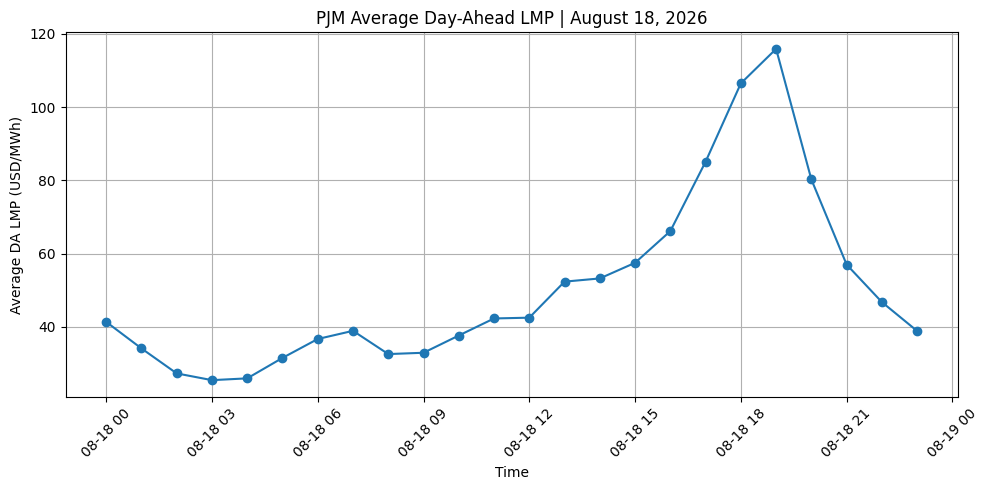

In [15]:
# Plot average hourly Day-Ahead LMP
plt.figure(figsize=(10, 5))  # Create the figure

plt.plot(
    hourly_da["Time"],  # X-axis: hour
    hourly_da["LMP"],   # Y-axis: average DA LMP
    marker="o"          # Show each hourly observation
)

plt.title("PJM Average Day-Ahead LMP | August 18, 2026")
plt.xlabel("Time")
plt.ylabel("Average DA LMP (USD/MWh)")

plt.xticks(rotation=45)  # Rotate time labels for readability
plt.grid(True)           # Add reference grid
plt.tight_layout()       # Prevent label clipping
plt.show()

In [16]:
# Identify the highest hourly average DA LMP
peak_da = hourly_da.loc[
    hourly_da["LMP"].idxmax()  # Return the row containing the maximum LMP
]

# Identify the lowest hourly average DA LMP
low_da = hourly_da.loc[
    hourly_da["LMP"].idxmin()  # Return the row containing the minimum LMP
]

print("Highest Average DA LMP")
print(peak_da)

print("\nLowest Average DA LMP")
print(low_da)

Highest Average DA LMP
Time    2026-08-18 19:00:00-04:00
LMP                    115.922074
Name: 19, dtype: object

Lowest Average DA LMP
Time    2026-08-18 03:00:00-04:00
LMP                     25.470947
Name: 3, dtype: object


In [17]:
# Calculate the daily average DA LMP for each hub
hub_avg_da = (
    da_818_clean
    .groupby("Location Name")["LMP"]  # Group observations by hub
    .mean()                           # Calculate the 24-hour average LMP
    .sort_values(ascending=False)     # Rank from highest to lowest
    .reset_index()                    # Convert hub names back into a column
)

hub_avg_da

,Location Name,LMP
0,DOMINION HUB,60.548143
1,WESTERN HUB,57.861126
2,WEST INT HUB,55.145190
3,AEP-DAYTON HUB,51.213945
4,OHIO HUB,51.164031
5,AEP GEN HUB,49.943088
6,EASTERN HUB,49.879177
7,ATSI GEN HUB,49.597542
8,NEW JERSEY HUB,46.011579
9,CHICAGO HUB,45.008246


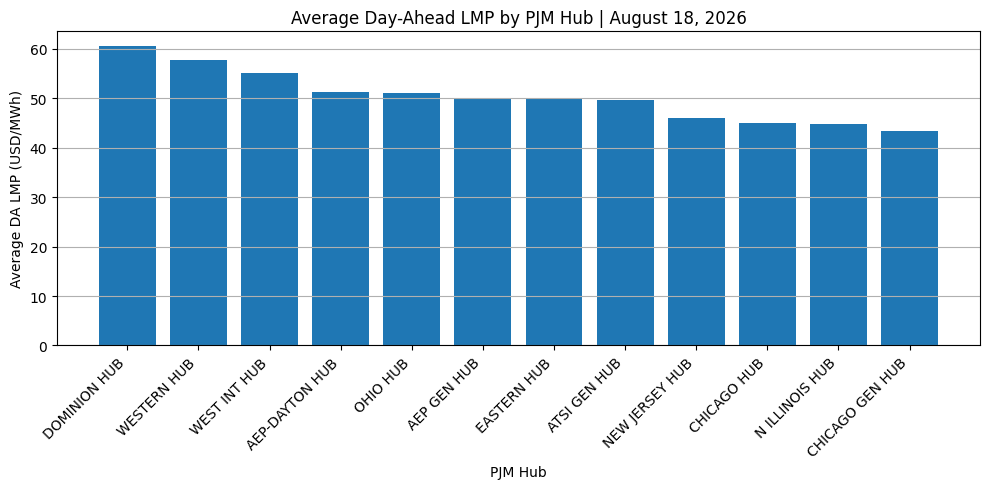

In [18]:
# Plot average Day-Ahead LMP by hub
plt.figure(figsize=(10, 5))  # Create the figure

plt.bar(
    hub_avg_da["Location Name"],  # X-axis: PJM hub
    hub_avg_da["LMP"]             # Y-axis: average DA LMP
)

plt.title("Average Day-Ahead LMP by PJM Hub | August 18, 2026")
plt.xlabel("PJM Hub")
plt.ylabel("Average DA LMP (USD/MWh)")

plt.xticks(rotation=45, ha="right")  # Rotate hub labels
plt.grid(axis="y")                   # Add horizontal reference lines
plt.tight_layout()
plt.show()

---

## 4. Congestion Analysis

Locational congestion can create meaningful price differences across PJM hubs. This section compares both the average congestion component and its hourly volatility.

In [19]:
# Calculate average congestion for each hub
hub_congestion = (
    da_818_clean
    .groupby("Location Name")["Congestion"]  # Group congestion by hub
    .mean()                                  # Calculate the daily average
    .sort_values(ascending=False)            # Rank from highest to lowest
    .reset_index()                           # Restore a regular DataFrame
)

# Rename the calculated metric
hub_congestion = hub_congestion.rename(
    columns={"Congestion": "Mean_Congestion"}  # Clarify that this is an average
)

hub_congestion

,Location Name,Mean_Congestion
0,DOMINION HUB,5.731671
1,WESTERN HUB,2.215147
2,WEST INT HUB,1.832942
3,AEP-DAYTON HUB,-1.737856
4,OHIO HUB,-1.838500
5,AEP GEN HUB,-1.947209
6,ATSI GEN HUB,-3.128900
7,N ILLINOIS HUB,-6.114403
8,CHICAGO HUB,-6.289165
9,EASTERN HUB,-6.764747


In [20]:
# Calculate congestion volatility for each hub
hub_congestion_std = (
    da_818_clean
    .groupby("Location Name")["Congestion"]  # Group congestion by hub
    .std()                                   # Calculate standard deviation
    .sort_values(ascending=False)            # Rank most volatile first
    .reset_index()                           # Restore a regular DataFrame
)

# Rename the calculated metric
hub_congestion_std = hub_congestion_std.rename(
    columns={"Congestion": "Congestion_Std"}  # Standard deviation of congestion
)

hub_congestion_std

,Location Name,Congestion_Std
0,EASTERN HUB,10.992945
1,NEW JERSEY HUB,10.200907
2,DOMINION HUB,7.352959
3,CHICAGO GEN HUB,7.061188
4,CHICAGO HUB,6.389096
5,N ILLINOIS HUB,6.277240
6,ATSI GEN HUB,5.816756
7,AEP GEN HUB,5.566155
8,OHIO HUB,5.404161
9,AEP-DAYTON HUB,5.379127


In [21]:
# Combine congestion level and congestion volatility
congestion_summary = pd.merge(
    hub_congestion,      # Average congestion by hub
    hub_congestion_std,  # Congestion standard deviation by hub
    on="Location Name"   # Match observations by hub
)

# Sort by average congestion
congestion_summary = congestion_summary.sort_values(
    "Mean_Congestion",       # Metric used for sorting
    ascending=False          # Highest values first
).reset_index(drop=True)

congestion_summary

,Location Name,Mean_Congestion,Congestion_Std
0,DOMINION HUB,5.731671,7.352959
1,WESTERN HUB,2.215147,4.431236
2,WEST INT HUB,1.832942,2.912732
3,AEP-DAYTON HUB,-1.737856,5.379127
4,OHIO HUB,-1.838500,5.404161
5,AEP GEN HUB,-1.947209,5.566155
6,ATSI GEN HUB,-3.128900,5.816756
7,N ILLINOIS HUB,-6.114403,6.277240
8,CHICAGO HUB,-6.289165,6.389096
9,EASTERN HUB,-6.764747,10.992945


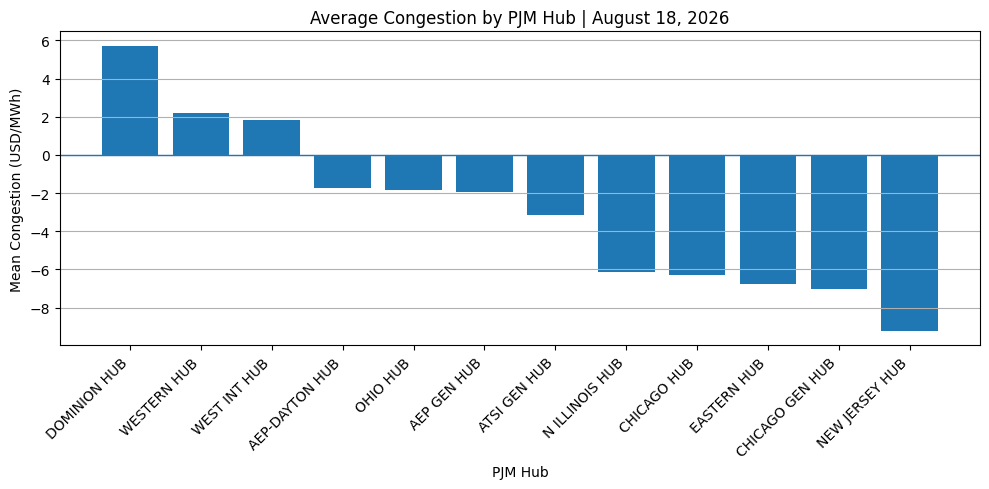

In [22]:
# Plot average congestion by hub
plt.figure(figsize=(10, 5))  # Create the figure

plt.bar(
    congestion_summary["Location Name"],   # X-axis: PJM hub
    congestion_summary["Mean_Congestion"]  # Y-axis: average congestion
)

plt.axhline(
    y=0,         # Reference line separating positive and negative congestion
    linewidth=1
)

plt.title("Average Congestion by PJM Hub | August 18, 2026")
plt.xlabel("PJM Hub")
plt.ylabel("Mean Congestion (USD/MWh)")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

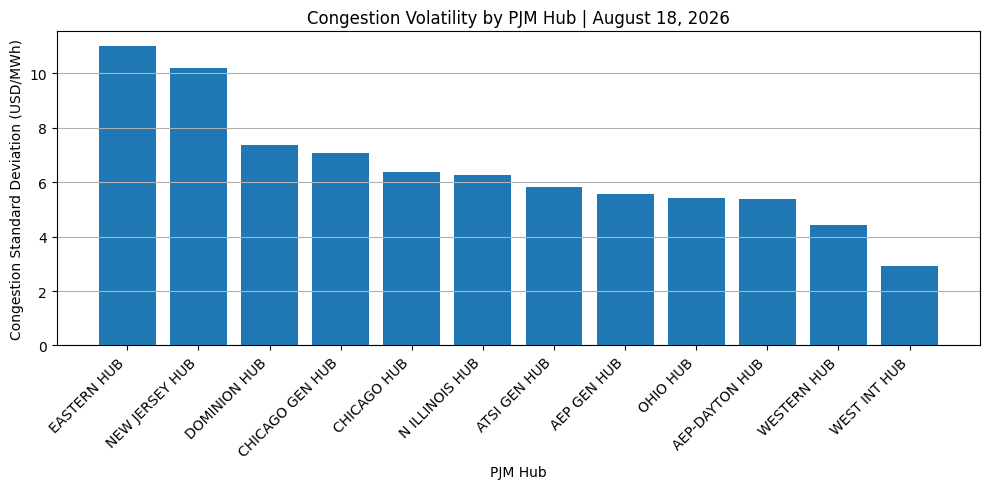

In [23]:
# Sort hubs by congestion volatility
congestion_std_plot = congestion_summary.sort_values(
    "Congestion_Std",       # Sort by standard deviation
    ascending=False         # Most volatile first
).reset_index(drop=True)

# Plot congestion volatility
plt.figure(figsize=(10, 5))  # Create the figure

plt.bar(
    congestion_std_plot["Location Name"],  # X-axis: PJM hub
    congestion_std_plot["Congestion_Std"]  # Y-axis: congestion volatility
)

plt.title("Congestion Volatility by PJM Hub | August 18, 2026")
plt.xlabel("PJM Hub")
plt.ylabel("Congestion Standard Deviation (USD/MWh)")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

---

## 5. Load vs Price

This section examines the relationship between PJM system load and the average Day-Ahead LMP across the selected hubs.

In [24]:
# Remove timezone information to align timestamps across datasets
hourly_da["Time"] = hourly_da["Time"].dt.tz_localize(
    None  # Preserve the clock time while removing timezone metadata
)

# Merge actual system load with hourly average DA LMP
load_price = pd.merge(
    actual_load,  # Actual hourly PJM load
    hourly_da,    # Average hourly DA LMP
    on="Time"     # Match observations by hour
)

load_price.head()

,Time,Actual_MW,LMP
0,2026-08-18 00:00:00,100226.472,41.381956
1,2026-08-18 01:00:00,95424.357,34.133116
2,2026-08-18 02:00:00,91962.251,27.313014
3,2026-08-18 03:00:00,89717.963,25.470947
4,2026-08-18 04:00:00,89427.081,25.962052


In [25]:
# Calculate the correlation between system load and DA LMP
load_price_corr = load_price[
    ["Actual_MW", "LMP"]  # Select the two variables
].corr()                  # Calculate the correlation matrix

load_price_corr

,Actual_MW,LMP
Actual_MW,1.000000,0.765946
LMP,0.765946,1.000000


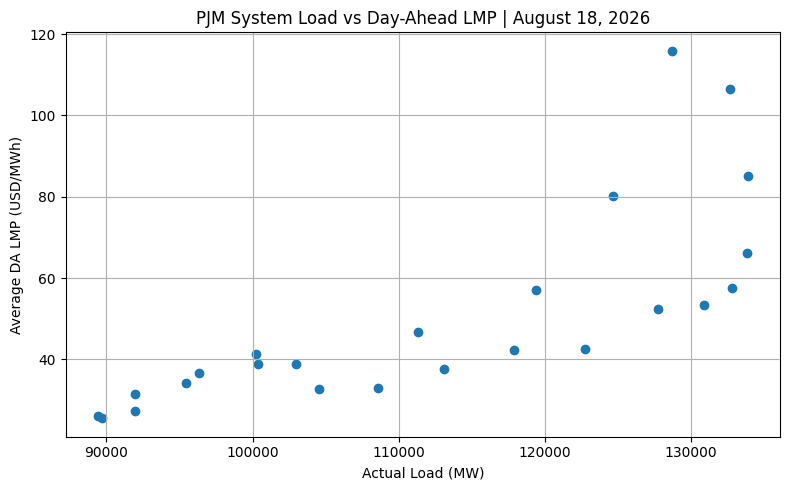

In [26]:
# Plot actual system load against average DA LMP
plt.figure(figsize=(8, 5))  # Create the figure

plt.scatter(
    load_price["Actual_MW"],  # X-axis: actual system load
    load_price["LMP"]         # Y-axis: average DA LMP
)

plt.title("PJM System Load vs Day-Ahead LMP | August 18, 2026")
plt.xlabel("Actual Load (MW)")
plt.ylabel("Average DA LMP (USD/MWh)")

plt.grid(True)
plt.tight_layout()
plt.show()

### Key Finding

Actual PJM load and average Day-Ahead LMP showed a strong positive correlation of approximately **0.77**.

However, peak load occurred at **17:00**, while peak Day-Ahead LMP occurred at **19:00**. This indicates that system load is an important price driver, but does not independently explain hourly LMP movements.

---

## 6. Load Forecast Accuracy

The selected forecast vintage was generated at **23:45 on August 17**, before the start of the August 18 operating day.

Forecast performance is evaluated against PJM's actual metered RTO load using MAE and MAPE.

In [27]:
# Merge forecasted and actual system load
forecast_compare = pd.merge(
    forecast_818,  # Pre-operating-day load forecast
    actual_load,   # Actual metered system load
    on="Time"      # Match observations by hour
)

# Calculate signed forecast error
forecast_compare["Forecast_Error"] = (
    forecast_compare["Actual_MW"]
    - forecast_compare["Forecast_MW"]  # Positive values indicate underforecasting
)

# Calculate absolute forecast error
forecast_compare["Absolute_Error"] = (
    forecast_compare["Forecast_Error"].abs()  # Ignore error direction
)

forecast_compare.head()

,Time,Forecast_MW,Actual_MW,Forecast_Error,Absolute_Error
0,2026-08-18 00:00:00,98657,100226.472,1569.472,1569.472
1,2026-08-18 01:00:00,93584,95424.357,1840.357,1840.357
2,2026-08-18 02:00:00,90139,91962.251,1823.251,1823.251
3,2026-08-18 03:00:00,87825,89717.963,1892.963,1892.963
4,2026-08-18 04:00:00,87415,89427.081,2012.081,2012.081


In [28]:
# Calculate Mean Absolute Error
forecast_mae = forecast_compare[
    "Absolute_Error"
].mean()  # Average absolute hourly error in MW

# Calculate hourly absolute percentage error
forecast_compare["Absolute_Percentage_Error"] = (
    forecast_compare["Absolute_Error"]
    / forecast_compare["Actual_MW"]
    * 100  # Convert hourly error into a percentage of actual load
)

# Calculate Mean Absolute Percentage Error
forecast_mape = forecast_compare[
    "Absolute_Percentage_Error"
].mean()  # Average percentage error

print("MAE:", forecast_mae, "MW")
print("MAPE:", forecast_mape, "%")

MAE: 2542.0697083333357 MW
MAPE: 2.226393854662302 %


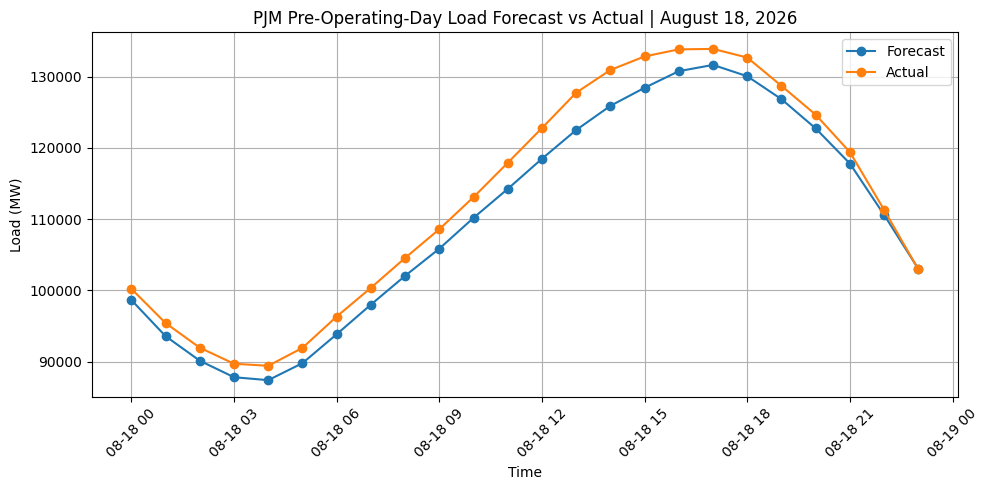

In [29]:
# Compare forecasted and actual PJM load
plt.figure(figsize=(10, 5))  # Create the figure

plt.plot(
    forecast_compare["Time"],         # X-axis: time
    forecast_compare["Forecast_MW"],  # Forecast load
    marker="o",
    label="Forecast"
)

plt.plot(
    forecast_compare["Time"],       # X-axis: time
    forecast_compare["Actual_MW"],  # Actual load
    marker="o",
    label="Actual"
)

plt.title("PJM Pre-Operating-Day Load Forecast vs Actual | August 18, 2026")
plt.xlabel("Time")
plt.ylabel("Load (MW)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Key Finding

The selected pre-operating-day PJM RTO load forecast captured the overall daily load profile, but underestimated actual system load during most hours.

The largest forecast misses occurred during the afternoon peak period.

**MAE:** approximately **2.54 GW**  
**MAPE:** approximately **2.23%**

---

## 7. Day-Ahead vs Real-Time Spread Analysis

The DA/RT spread measures how much Real-Time prices differed from prices established in the Day-Ahead Market.

A positive spread indicates that Real-Time LMP exceeded Day-Ahead LMP, while a negative spread indicates that Real-Time LMP was lower.

In [30]:
# Select the Day-Ahead columns required for spread analysis
da_spread = da_818_clean[
    ["Time", "Location Name", "LMP"]  # Time, hub, and Day-Ahead LMP
].copy()

# Rename the Day-Ahead price column
da_spread = da_spread.rename(
    columns={"LMP": "DA_LMP"}  # Distinguish DA price from RT price
)

# Remove timezone metadata before merging
da_spread["Time"] = da_spread["Time"].dt.tz_localize(
    None  # Align DA timestamps with RT timestamps
)

# Merge DA and RT prices by both hour and hub
da_rt = pd.merge(
    da_spread,
    rt[["Time", "Location Name", "RT_LMP"]],
    on=["Time", "Location Name"]  # Both time and location must match
)

# Calculate the DA/RT spread
da_rt["Spread"] = (
    da_rt["RT_LMP"] - da_rt["DA_LMP"]  # Positive = RT above DA
)

da_rt.head()

,Time,Location Name,DA_LMP,RT_LMP,Spread
0,2026-08-18 00:00:00,AEP GEN HUB,41.657713,37.980132,-3.677581
1,2026-08-18 01:00:00,AEP GEN HUB,34.694680,30.540263,-4.154417
2,2026-08-18 02:00:00,AEP GEN HUB,28.535563,27.896140,-0.639423
3,2026-08-18 03:00:00,AEP GEN HUB,26.963486,25.545110,-1.418376
4,2026-08-18 04:00:00,AEP GEN HUB,27.416214,25.323004,-2.093210


In [31]:
# Find the largest positive DA/RT spread
max_positive_spread = da_rt.loc[
    da_rt["Spread"].idxmax()  # Row containing the maximum spread
]

# Find the largest negative DA/RT spread
max_negative_spread = da_rt.loc[
    da_rt["Spread"].idxmin()  # Row containing the minimum spread
]

print("Largest Positive Spread")
print(max_positive_spread)

print("\nLargest Negative Spread")
print(max_negative_spread)

Largest Positive Spread
Time             2026-08-18 19:00:00
Location Name           DOMINION HUB
DA_LMP                    156.440659
RT_LMP                    275.290983
Spread                    118.850324
Name: 139, dtype: object

Largest Negative Spread
Time             2026-08-18 18:00:00
Location Name            EASTERN HUB
DA_LMP                    137.339618
RT_LMP                     43.819308
Spread                     -93.52031
Name: 162, dtype: object


In [32]:
# Calculate average spread for each hub
hub_spread_mean = (
    da_rt
    .groupby("Location Name")["Spread"]  # Group observations by hub
    .mean()                              # Calculate average spread
    .sort_values(ascending=False)        # Rank highest average spread first
    .reset_index()
)

# Rename the calculated metric
hub_spread_mean = hub_spread_mean.rename(
    columns={"Spread": "Mean_Spread"}
)

hub_spread_mean

,Location Name,Mean_Spread
0,AEP GEN HUB,4.630505
1,AEP-DAYTON HUB,3.918547
2,OHIO HUB,3.396097
3,ATSI GEN HUB,2.536549
4,NEW JERSEY HUB,1.011750
5,WEST INT HUB,0.489507
6,WESTERN HUB,-0.495359
7,DOMINION HUB,-0.776265
8,EASTERN HUB,-3.107721
9,N ILLINOIS HUB,-3.965325


In [33]:
# Calculate spread volatility for each hub
hub_spread_std = (
    da_rt
    .groupby("Location Name")["Spread"]  # Group observations by hub
    .std()                               # Calculate standard deviation
    .sort_values(ascending=False)        # Rank most volatile first
    .reset_index()
)

# Rename the calculated metric
hub_spread_std = hub_spread_std.rename(
    columns={"Spread": "Spread_Std"}
)

hub_spread_std

,Location Name,Spread_Std
0,DOMINION HUB,33.174977
1,WESTERN HUB,31.609739
2,WEST INT HUB,29.874566
3,ATSI GEN HUB,28.585744
4,AEP-DAYTON HUB,28.382282
5,AEP GEN HUB,28.258666
6,OHIO HUB,28.076127
7,EASTERN HUB,27.901492
8,CHICAGO HUB,26.051586
9,N ILLINOIS HUB,25.896530


In [34]:
# Combine average spread and spread volatility
spread_summary = pd.merge(
    hub_spread_mean,
    hub_spread_std,
    on="Location Name"  # Match results by hub
)

spread_summary = spread_summary.sort_values(
    "Mean_Spread",
    ascending=False
).reset_index(drop=True)

spread_summary

,Location Name,Mean_Spread,Spread_Std
0,AEP GEN HUB,4.630505,28.258666
1,AEP-DAYTON HUB,3.918547,28.382282
2,OHIO HUB,3.396097,28.076127
3,ATSI GEN HUB,2.536549,28.585744
4,NEW JERSEY HUB,1.011750,21.487925
5,WEST INT HUB,0.489507,29.874566
6,WESTERN HUB,-0.495359,31.609739
7,DOMINION HUB,-0.776265,33.174977
8,EASTERN HUB,-3.107721,27.901492
9,N ILLINOIS HUB,-3.965325,25.896530


In [35]:
# Calculate absolute DA/RT spread
da_rt["Abs_Spread"] = da_rt[
    "Spread"
].abs()  # Measure spread magnitude without direction

# Calculate average absolute spread across hubs for each hour
hourly_abs_spread = (
    da_rt
    .groupby("Time")["Abs_Spread"]  # Group all 12 hubs by hour
    .mean()                         # Calculate average absolute spread
    .reset_index()
)

hourly_abs_spread

,Time,Abs_Spread
0,2026-08-18 00:00:00,5.022307
1,2026-08-18 01:00:00,5.240727
2,2026-08-18 02:00:00,1.056299
3,2026-08-18 03:00:00,1.333255
4,2026-08-18 04:00:00,2.454722
5,2026-08-18 05:00:00,3.809627
6,2026-08-18 06:00:00,13.156771
7,2026-08-18 07:00:00,3.634471
8,2026-08-18 08:00:00,3.407687
9,2026-08-18 09:00:00,3.111997


In [36]:
# Calculate average signed spread across hubs for each hour
hourly_mean_spread = (
    da_rt
    .groupby("Time")["Spread"]  # Group all 12 hubs by hour
    .mean()                     # Preserve positive and negative direction
    .reset_index()
)

# Combine signed and absolute hourly spread
hourly_spread_summary = pd.merge(
    hourly_mean_spread,
    hourly_abs_spread,
    on="Time"  # Match observations by hour
)

# Rename the metrics
hourly_spread_summary = hourly_spread_summary.rename(
    columns={
        "Spread": "Mean_Spread",
        "Abs_Spread": "Mean_Abs_Spread"
    }
)

hourly_spread_summary

,Time,Mean_Spread,Mean_Abs_Spread
0,2026-08-18 00:00:00,-5.022307,5.022307
1,2026-08-18 01:00:00,-5.240727,5.240727
2,2026-08-18 02:00:00,-0.078289,1.056299
3,2026-08-18 03:00:00,-0.781912,1.333255
4,2026-08-18 04:00:00,-2.205652,2.454722
5,2026-08-18 05:00:00,-2.528318,3.809627
6,2026-08-18 06:00:00,8.846838,13.156771
7,2026-08-18 07:00:00,1.085551,3.634471
8,2026-08-18 08:00:00,-1.952908,3.407687
9,2026-08-18 09:00:00,-2.849802,3.111997


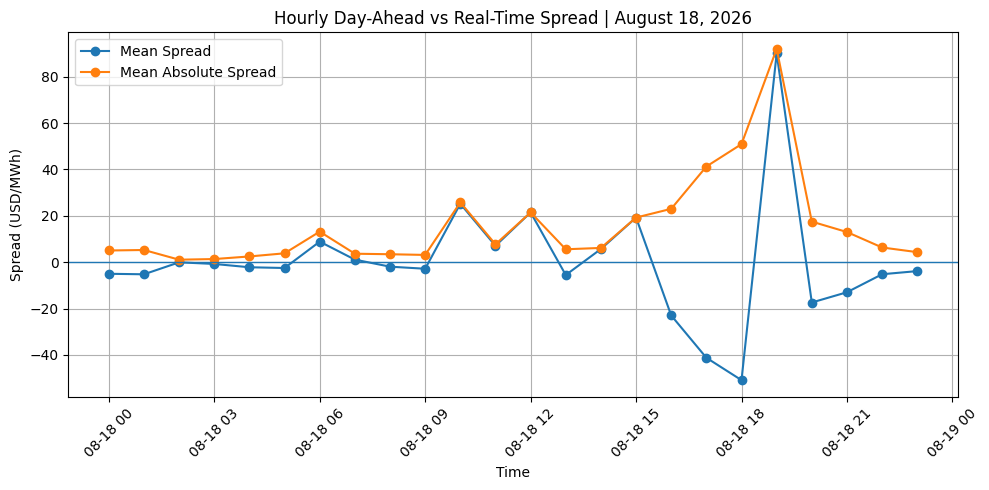

In [37]:
# Plot hourly DA/RT spread behavior
plt.figure(figsize=(10, 5))  # Create the figure

plt.plot(
    hourly_spread_summary["Time"],
    hourly_spread_summary["Mean_Spread"],      # Signed average spread
    marker="o",
    label="Mean Spread"
)

plt.plot(
    hourly_spread_summary["Time"],
    hourly_spread_summary["Mean_Abs_Spread"],  # Average spread magnitude
    marker="o",
    label="Mean Absolute Spread"
)

plt.axhline(
    y=0,         # Reference line between positive and negative spreads
    linewidth=1
)

plt.title("Hourly Day-Ahead vs Real-Time Spread | August 18, 2026")
plt.xlabel("Time")
plt.ylabel("Spread (USD/MWh)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Key Finding

Day-Ahead and Real-Time prices diverged most strongly during the evening peak period.

At **18:00**, Real-Time prices were substantially below Day-Ahead prices on average. One hour later, at **19:00**, the direction reversed sharply and Real-Time prices moved well above Day-Ahead prices.

The largest hourly mean absolute spread occurred at **19:00**, at approximately **91.98 USD/MWh**.

---

## 8. Fuel Mix vs Day-Ahead LMP

This section examines how hourly generation from different fuel categories co-moved with average Day-Ahead LMP.

In [38]:
# Merge generation mix with hourly average DA LMP
fuel_lmp = pd.merge(
    fuel,       # Hourly generation by fuel type
    hourly_da,  # Hourly average DA LMP
    on="Time"   # Match observations by hour
)

fuel_lmp.head()

,Time,Coal,Gas,Hydro,Multiple Fuels,Nuclear,Oil,Other Renewables,Solar,Storage,Wind,LMP
0,2026-08-18 00:00:00,18735,53040,333,2009,32584,250,645,47,11,530,41.381956
1,2026-08-18 01:00:00,18253,50457,327,1989,32601,218,636,47,11,551,34.133116
2,2026-08-18 02:00:00,17296,48530,389,1885,32614,222,647,47,11,533,27.313014
3,2026-08-18 03:00:00,16525,47021,405,1698,32634,226,634,47,11,675,25.470947
4,2026-08-18 04:00:00,15981,46774,431,1657,32648,225,638,47,11,586,25.962052


In [39]:
# Define the generation categories used in the correlation analysis
fuel_cols = [
    "Coal",
    "Gas",
    "Hydro",
    "Multiple Fuels",
    "Nuclear",
    "Oil",
    "Other Renewables",
    "Solar",
    "Storage",
    "Wind"
]

# Calculate the correlation between each generation category and DA LMP
fuel_corr = (
    fuel_lmp[fuel_cols]              # Select generation columns
    .corrwith(fuel_lmp["LMP"])       # Correlate each column with DA LMP
    .sort_values(ascending=False)    # Rank strongest positive correlation first
)

fuel_corr

,0
Hydro,0.937468
Storage,0.869244
Gas,0.858322
Oil,0.840139
Wind,0.794065
Coal,0.793255
Multiple Fuels,0.702326
Solar,0.166809
Other Renewables,-0.634654
Nuclear,-0.741311


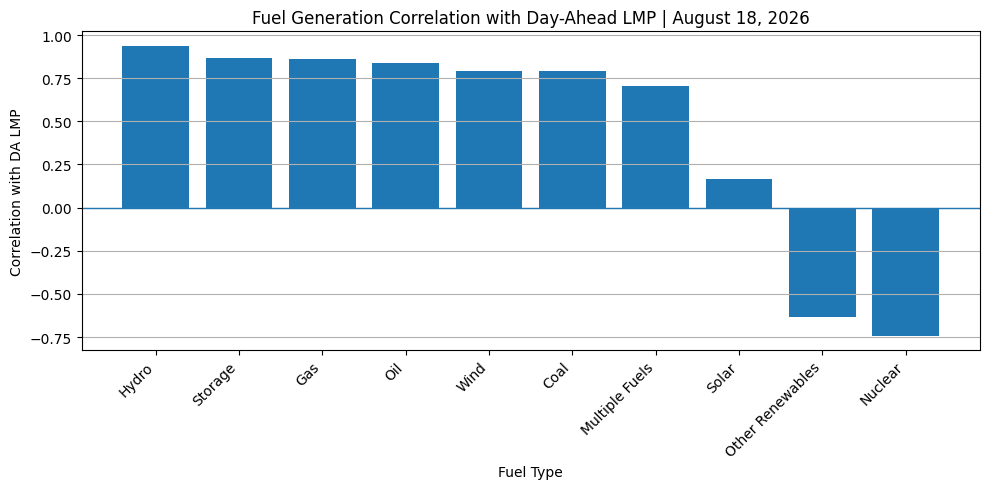

In [40]:
# Convert correlation results into a DataFrame
fuel_corr_plot = fuel_corr.reset_index()

# Rename the columns
fuel_corr_plot.columns = [
    "Fuel_Type",
    "Correlation"
]

# Plot fuel-generation correlation with DA LMP
plt.figure(figsize=(10, 5))  # Create the figure

plt.bar(
    fuel_corr_plot["Fuel_Type"],    # X-axis: generation category
    fuel_corr_plot["Correlation"]   # Y-axis: correlation with DA LMP
)

plt.axhline(
    y=0,         # Reference line between positive and negative correlation
    linewidth=1
)

plt.title("Fuel Generation Correlation with Day-Ahead LMP | August 18, 2026")
plt.xlabel("Fuel Type")
plt.ylabel("Correlation with DA LMP")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Key Finding

Hydro, Storage, Gas, and Oil generation showed strong positive correlations with average Day-Ahead LMP during the analysis day, while Nuclear generation showed a negative correlation.

These results describe hourly co-movement and should not be interpreted as evidence of causation.

---

## 9. Key Findings

### Market Price Behavior
Average Day-Ahead LMP across the 12 selected PJM hubs peaked at approximately **115.92 USD/MWh at 19:00** and reached its minimum of approximately **25.47 USD/MWh at 03:00**.

### Geographic Price Differences
Day-Ahead prices varied meaningfully across hubs. **Dominion Hub** recorded the highest daily average LMP, while **Chicago Gen Hub** recorded the lowest.

### Congestion
Congestion effects differed substantially by location. Dominion Hub experienced positive average congestion, while New Jersey Hub experienced strongly negative average congestion. Eastern Hub and New Jersey Hub showed the highest congestion volatility.

### Load and Price
Actual PJM system load and average Day-Ahead LMP had a correlation of approximately **0.77**. However, peak system load occurred at **17:00**, while peak Day-Ahead LMP occurred at **19:00**, demonstrating that load alone does not explain hourly price movements.

### Load Forecast Performance
The selected pre-operating-day load forecast underestimated actual system load during most hours. Forecast performance was approximately:

**MAE:** 2.54 GW  
**MAPE:** 2.23%

### Day-Ahead vs Real-Time Price Risk
DA and RT prices diverged sharply during the evening period. The largest hourly mean absolute spread occurred at **19:00**, reaching approximately **91.98 USD/MWh**.

### Generation Mix
Hydro, Storage, Gas, and Oil generation showed strong positive correlations with Day-Ahead LMP during the analysis day, while Nuclear generation showed a negative correlation. These relationships represent correlation rather than causation.

---

## Conclusion

This analysis demonstrates how PJM electricity prices reflect the interaction of system demand, transmission congestion, Day-Ahead expectations, Real-Time system conditions, and generation behavior.

The results also highlight the importance of analyzing both price levels and price uncertainty. Average prices alone can hide significant hourly volatility, particularly in congestion and Day-Ahead versus Real-Time spreads.